---
title: "Three-way catalyst: Voltz CO and propylene oxidation kinetics (Voltz et al., 1973)"
description: "The self-inhibited Langmuir-Hinshelwood rates behind most catalytic-converter models, their rate maximum in CO, and their integral reactor rebuilt against the paper's own curves and data."
categories: [sec:C, struct:S1, struct:S2, tier:T0, data:tier4]
date: 2026-11-19
---

# Three-way catalyst: Voltz CO and propylene oxidation kinetics

**Catalog ID:** `C2.13` · **Structures:** `S1`, `S2` · **Tier:** T0

Voltz, Morgan, Liederman and Jacob (1973) measured CO and propylene oxidation
on a pelleted platinum-alumina catalyst in an isothermal integral reactor and
fitted rate equations in which CO, propylene and NO inhibit both oxidations.
Their Table I is still the kinetics of most catalytic-converter models (the
monolith of `I1.2` uses it with recalibrated rate constants). This page
transcribes the rate law, locates its rate maximum in CO, rebuilds the
integral reactor of their eq 1 with pymrm, and tests it against the paper's
own calculated curves and measurements of Figures 19 and 20.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.20.3"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "C2.13-voltz-co-propylene-oxidation"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, Markdown, display
from gallery_utils import Claims, cite_data, load_data, load_meta
from pymrm.checks import observed_orders
from model import (IntegralReactor, co_rate_maximum, co_rate_maximum_closed_form,
                   march, rate_constants, rates, tau_at_conversion)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
I12 = "I1.2-catalytic-converter-lightoff"


def show(styler, uuid):
    """Display a styled table with a pinned id, so two runs print the same HTML."""
    display(HTML(styler.set_uuid(uuid).to_html()))

## Background

A car's exhaust converter has to burn CO and unburnt hydrocarbons in a few
milliseconds of contact with platinum, starting from a cold engine. The
chemistry that sets its warm-up is unusual: CO adsorbs so strongly on
platinum that it blocks the oxygen it needs, so over most conditions adding
CO *slows* the CO oxidation. A rate that falls with its own reactant gives a
rate maximum in concentration, a converter whose light-off is delayed by a
rich feed, and multiple steady states in a monolith.

Voltz et al. set out to build a rate law good enough for a converter model
(the converter model of Kuo et al. 1971 and 1972). They ran factorial
experiments at 400 to 700 °F with synthetic gas (CO, propylene, O2, NO, CO2,
10 % water) and engine exhaust, and fitted Langmuir-Hinshelwood forms by
integrating the integral-reactor design equation through the bed for every run
and minimising the squared conversion errors by pattern search.

## The published model

The isothermal integral reactor (their eq 1), with $x$ the fractional bed
length, $V$ the catalyst volume, $F$ the gas flow (eq 1 defines it as "gas flow (ft3 of fluid/sec)") and $Y_i$ the mole fraction:

$$
\frac{V}{F}\int_0^1 \mathrm{d}x = \int_{Y_{i1}}^{Y_{i2}} \frac{\mathrm{d}Y_i}{r_i} .
$$

The rates on catalyst volume (eqs 2 to 4):

$$
r_{\rm CO} = -\frac{k_{r_1}(\mathrm{CO})(\mathrm{O_2})}{R(\theta)},\qquad
r_{\rm C_3H_6} = -\frac{k_{r_2}(\mathrm{C_3H_6})(\mathrm{O_2})}{R(\theta)},
$$

$$
R(\theta) = [1 + k_{a_1}(\mathrm{CO}) + k_{a_2}(\mathrm{C_3H_6})]^2
\,[1 + k_{a_3}(\mathrm{CO})^2(\mathrm{C_3H_6})^2]\,[1 + k_{a_4}(\mathrm{NO})^{0.7}] ,
$$

with Arrhenius constants $k = k^0 \exp[-(E/R_g)/(T_s + 460)]$ (eqs 5 and 6),
$T_s$ in °F. The paper defines the units below eq 4: (CO) and (O2) in mole per
cent, (NO) in ppm, and "(C3H6) = ppm of propylene (as C6 FID)", that is, the
flame-ionisation reading expressed as hexane. One propylene molecule carries
half the carbon of a hexane molecule, so the rate equations take the
propylene concentration in ppm divided by 2. The figure legends give
"HC, ppm", and the text gives the same feeds as "ppm of C3H6". Which of the two the constants were fitted with is tested
below against the paper's own calculated curves.

| Symbol | Name in `model.py` |
|---|---|
| $k^0_{r_1}, k^0_{r_2}, k^0_{a_1}\ldots k^0_{a_4}$ | `par["k0_r1"]` ... `par["k0_a4"]` |
| $E_{r_j}/R_g$, $E_{a_i}/R_g$ (°R) | `par["E_r1"]` ... `par["E_a4"]` |
| $R(\theta)$ | `resistance` |
| $r_{\rm CO}$, $r_{\rm C_3H_6}$ | `rates` |
| eq 1 | `IntegralReactor` (pymrm), `march` (`solve_ivp`) |
| $V/F$ (s) | `tau` |
| ppm basis divisor (2 for C6) | `hc_basis` |

## Parameters and assumptions

Table I is loaded from its CSV into one dictionary `par` that every function
takes. Assumptions, each stated where the paper is silent:

- the bed is isothermal at the salt-bath temperature (the paper's bed
  thermocouples showed this except at the highest CO and propylene together);
- O2 is consumed by the stoichiometry CO + ½ O2 and C3H6 + 9/2 O2 (eq 1 is
  written per reactant; whether the authors depleted O2 is not stated, so the
  scatter of $a$ is also computed without depletion, below);
- no NO conversion (the paper found none) and no CO formed from propylene;
- the space velocity of the figures, litres per minute per gram, and $V/F$ of
  eq 1 differ by a factor $a = \tau\,\mathrm{SV}$ that depends on the
  unstated gas-volume basis and on the catalyst volume per gram. The page
  infers $a$ from the authors' calculated curves and compares it with the
  value $a_0$ for $F$ at 550 °F (a flow of fluid, as eq 1 says) with the space
  velocity in litres at 0 °C, and the stated bulk density of 0.72 g/cm³.

In [3]:
table1 = load_data("voltz-1973-table1.csv", page=PAGE)
PAR = dict(zip(table1.symbol, table1.value.astype(float)))
cond = load_data("voltz-1973-fig19-fig20-conditions.csv", page=PAGE).set_index("curve")
COND = {c: tuple(float(v) for v in row) for c, row in cond.iterrows()}
T_FIG = 550.0                      # degF, Figures 19 and 20
RHO_BULK = 0.72                    # g/cm3, bulk density of the catalyst (page 295)
T_ZERO_C, T_FIG_K = 273.15, (T_FIG - 32.0) / 1.8 + 273.15
# tau * SV if SV is litres at 0 degC and V the bulk volume of 1 g: s L/(min g)
A_ZERO_C = (1.0 / RHO_BULK) / (1000.0 / 60.0) * T_ZERO_C / T_FIG_K
show(table1.style.hide(axis="index"), "c2131")
print(cite_data(load_meta("voltz-1973-table1.csv", page=PAGE)))

symbol,value,unit,description
k0_r1,1830000000000.000000,1/(s mol% O2),frequency factor of the CO rate constant k_r1
k0_r2,38000000000000.000000,1/(s mol% O2),frequency factor of the C3H6 rate constant k_r2
k0_a1,0.655000,1/(mol% CO),frequency factor of the CO adsorption constant k_a1
k0_a2,0.002080,1/ppm,frequency factor of the C3H6 adsorption constant k_a2
k0_a3,0.000000,1/(mol% ppm)^2,frequency factor of the combined CO-C3H6 constant k_a3
k0_a4,30.200000,1/ppm^0.7,frequency factor of the NO adsorption constant k_a4
E_r1,22600.000000,degR,E/R_g of k_r1
E_r2,26200.000000,degR,E/R_g of k_r2
E_a1,-1730.000000,degR,E/R_g of k_a1
E_a2,-650.000000,degR,E/R_g of k_a2


Voltz, S. E.; Morgan, C. R.; Liederman, D.; Jacob, S. M. (1973) — Industrial & Engineering Chemistry Product Research and Development 12(4) 294-301 — doi:10.1021/i360048a006 — table


## The data

Three datasets from this paper, each with a provenance sidecar, regenerated
by `extract_figures.py` from a local copy of the PDF:

- `voltz-1973-fig19-fig20.csv`: the measured conversions (markers) of
  Figures 19 (CO) and 20 (propylene) at 550 °F for the seven synthetic-gas
  compositions A to G of `voltz-1973-fig19-fig20-conditions.csv`. Table I was
  fitted to these runs among others, so agreement with them is reproduction
  of the fit, not validation.
- `voltz-1973-calculated-lines.csv`: where the authors' own calculated lines
  cross 50 % (Figure 19) or 40 % (Figure 20) conversion, 13 points. They test
  whether this page computes what the authors computed.

One dataset borrowed from `I1.2`: `oh-cavendish-1982-parameters.csv`, Oh and
Cavendish's (1982) constants. `I1.2` states about these rows that Oh and
Cavendish recalibrated only the pre-exponential factors of the two rate
constants against their own recycle-reactor data and kept Voltz's activation
energies and adsorption constants unchanged, in mole-fraction units and
kelvin. The page tests that statement for every adsorption constant and both
activation temperatures; the recalibrated pre-exponentials (per unit platinum
area) are not comparable and are not used.

In [4]:
obs = load_data("voltz-1973-fig19-fig20.csv", page=PAGE)
lines = load_data("voltz-1973-calculated-lines.csv", page=PAGE)
oc = load_data("oh-cavendish-1982-parameters.csv", page=I12).set_index("symbol")
print(cite_data(load_meta("voltz-1973-fig19-fig20.csv", page=PAGE)))
print(f"{len(obs)} markers ({(obs.figure == 19).sum()} CO, {(obs.figure == 20).sum()} "
      f"propylene); {len(lines)} calculated-line points")

Voltz, S. E.; Morgan, C. R.; Liederman, D.; Jacob, S. M. (1973) — Industrial & Engineering Chemistry Product Research and Development 12(4) 294-301 — doi:10.1021/i360048a006 — digitised from Figure 19 (CO conversion, page 299) and Figure 20 (propylene conversion, page 300)
107 markers (55 CO, 52 propylene); 13 calculated-line points


## PyMRM implementation

Eq 1 is a plug-flow reactor on the fractional bed length $x\in[0,1]$ with the
rates multiplied by the space time $\tau = V/F$. `IntegralReactor` solves it
as a steady convection problem: CO, the hydrocarbon and O2 scaled by their
inlet values on a `(n, 3)` grid, first-order upwind convection at unit
velocity (`construct_convflux_upwind`, `construct_div` with `nu=0`), inlet
values fixed at $x=0$ and `{"outflow": True}` at $x=1$, the rates as a
pointwise source differentiated by `NumJac((n, 3))`, and one `newton` solve
with the unknowns bounded below by zero. The outlet conversion is read from
the outlet face with `compute_boundary_values`. The space time at a given
conversion is a root of the outlet conversion found with
`pymrm.checks.find_roots`.

All studies sit in one function of the parameters and choices, so every
break-table row below is the same computation with one argument changed.

In [5]:
N_CELLS = 800


def a_per_point(par, hc_basis, o2_consumed, n):
    """tau * SV of every calculated-line point: SV read off the paper's line,
    tau the space time at which this page's reactor reaches the same conversion."""
    out = []
    for _, ln in lines.iterrows():
        rx = IntegralReactor(par, T_FIG, COND[ln.curve], hc_basis=hc_basis,
                             o2_consumed=o2_consumed, n=n)
        j = 0 if ln.figure == 19 else 1
        tau = tau_at_conversion(lambda t: rx.solve(t)[j], ln.conversion_pct, 1e-4, 1.0)
        out.append(tau * ln.space_velocity)
    return np.array(out)


def study(par=PAR, hc_basis=2.0, o2_consumed=True, n=N_CELLS, power=2,
          march_o2=True, ladder=(200, 400, 800, 1600), ratio=None, oc=oc):
    """Every number the page states, as a function of the parameters and choices."""
    m = {}
    k = rate_constants(par, T_FIG)
    m["kr1_550F"], m["ka1_550F"] = k["kr1"], k["ka1"]
    # Oh & Cavendish (I1.2): Voltz's constants in mole fractions and kelvin
    conv = {"K1": ("a1", 1e2), "K2": ("a2", 1e6), "K3": ("a3", 1e16), "K4": ("a4", 1e6 ** 0.7)}
    m["oc_K_pre_max_relgap"] = max(abs(par["k0_" + v] * f / oc.loc[K + "_A", "value"] - 1.0)
                                   for K, (v, f) in conv.items())
    pairs = [("E_" + v, K + "_dH_over_R") for K, (v, _) in conv.items()] \
        + [("E_r1", "k1_E_over_R"), ("E_r2", "k2_E_over_R")]
    m["oc_E_max_gap_K"] = max(abs(par[a] / 1.8 - oc.loc[b, "value"]) for a, b in pairs)
    # rate maximum in CO at 100 ppm propylene, no NO
    for T in (400.0, 550.0, 700.0):
        m[f"co_max_{T:.0f}F"] = co_rate_maximum(par, T, 100.0 / hc_basis, power=power)
    m["co_max_rise_min"] = min(m["co_max_550F"] / m["co_max_400F"],
                               m["co_max_700F"] / m["co_max_550F"]) - 1.0
    # every feed of Figures 19 and 20 against the maximum at its own propylene
    m["feed_over_max"] = [inlet[0] / co_rate_maximum(par, T_FIG, inlet[1] / hc_basis,
                                                     power=power)
                          for inlet in COND.values()]
    par0 = dict(par, k0_a3=0.0)
    m["co_max_closed_form_relgap"] = abs(
        co_rate_maximum(par0, T_FIG, 100.0 / hc_basis, power=power)
        / co_rate_maximum_closed_form(par0, T_FIG, 100.0 / hc_basis) - 1.0)
    # the reactor against the authors' calculated lines
    la = np.log10(a_per_point(par, hc_basis, o2_consumed, n))
    m["a_fit"] = 10 ** la.mean()
    m["a_spread_dex"] = la.std()
    dev = np.abs(la - la.mean())
    order = np.argsort(dev)            # rank the 13 named line points
    worst = lines.iloc[order[-1]]
    m["largest_dev_point"] = f"{worst.figure}{worst.curve}"
    m["largest_dev_margin_dex"] = dev[order[-1]] - dev[order[-2]]
    m["a_fit_over_a_0C"] = m["a_fit"] / A_ZERO_C
    other = np.log10(a_per_point(par, 3.0 - hc_basis, o2_consumed, n))  # the other basis
    m["a_spread_other_basis_dex"] = other.std()
    nod = np.log10(a_per_point(par, hc_basis, False, n))    # O2 not depleted in the rates
    m["a_spread_no_o2_dex"] = nod.std()
    m["a_fit_no_o2"] = 10 ** nod.mean()
    is20a = ((lines.figure == 20) & (lines.curve == "A")).to_numpy()
    if is20a.sum() != 1:
        raise ValueError("expected exactly one calculated-line point for Figure 20 curve A")
    m["dev_20A_dex"] = float((la - la.mean())[is20a][0])
    # the reactor against the measurements, with a from the lines
    for fig in (19, 20):
        err = []
        for c, g in obs[obs.figure == fig].groupby("curve"):
            rx = IntegralReactor(par, T_FIG, COND[c], hc_basis=hc_basis,
                                 o2_consumed=o2_consumed, n=n)
            j = 0 if fig == 19 else 1
            x = [rx.solve(m["a_fit"] / sv)[j] for sv in g.space_velocity]
            err.append(np.array(x) - g.conversion_pct.to_numpy())
        cur = [c for c, _ in obs[obs.figure == fig].groupby("curve")]
        errA = err[cur.index("A")]
        err = np.concatenate(err)
        m[f"bias_se_fig{fig}_pp"] = float(err.std(ddof=1) / np.sqrt(err.size))
        if fig == 20:
            m["rms_20A_pp"] = float(np.sqrt(np.mean(errA ** 2)))
            m["bias_20A_pp"] = float(errA.mean())
        m[f"rms_fig{fig}_pp"] = float(np.sqrt(np.mean(err ** 2)))
        m[f"bias_fig{fig}_pp"] = float(err.mean())
    # discretisation: pymrm against the solve_ivp march, and its observed order
    gaps = []
    for _, ln in lines.iterrows():
        tau = m["a_fit"] / ln.space_velocity
        j = 0 if ln.figure == 19 else 1
        rx = IntegralReactor(par, T_FIG, COND[ln.curve], hc_basis=hc_basis,
                             o2_consumed=o2_consumed, n=n)
        ref = march(par, T_FIG, COND[ln.curve], tau, hc_basis=hc_basis,
                    o2_consumed=o2_consumed and march_o2)
        gaps.append(abs(rx.solve(tau)[j] - ref[j]))
    m["pymrm_vs_march_max_pp"] = max(gaps)
    tau_a = m["a_fit"] / lines.space_velocity.iloc[0]          # curve A, Figure 19
    def outlet(nn):
        return IntegralReactor(par, T_FIG, COND["A"], hc_basis=hc_basis,
                               o2_consumed=o2_consumed, n=int(nn)).solve(tau_a)[0]

    try:
        ref_study = observed_orders(outlet, ladder, ratio=ratio)
    except ValueError:                  # a ladder that is not a constant refinement
        m["order_min"] = m["order_max"] = m["finest_difference_pp"] = float("nan")
    else:
        orders = np.asarray(ref_study["orders"], dtype=float)
        vals = np.asarray(ref_study["values"], dtype=float)
        m["order_min"], m["order_max"] = float(np.min(orders)), float(np.max(orders))
        m["finest_difference_pp"] = float(abs(vals[-1] - vals[-2]))
    m["co_max_rises_with_T"] = bool(m["co_max_rise_min"] > 0)
    m["feeds_above_max"] = int(np.sum(np.array(m["feed_over_max"]) > 1.0))
    return m


base = study()
claims.count("feeds_above_max", base["feed_over_max"], threshold=1.0, min_margin=0.05,
             note="CO in each feed over the CO of the rate maximum at its propylene")

7

## Results

### The rate maximum in CO

At fixed propylene and O2, $r_{\rm CO}\propto \mathrm{CO}/R(\theta)$ rises
linearly at low CO and falls once CO covers the surface.
The maximum is the root of $\mathrm{d}\ln r_{\rm CO}/\mathrm{d\,CO}$; without
the $k_{a_3}$ term it is $\mathrm{CO}^* = (1 + k_{a_2}\mathrm{C_3H_6})/k_{a_1}$.

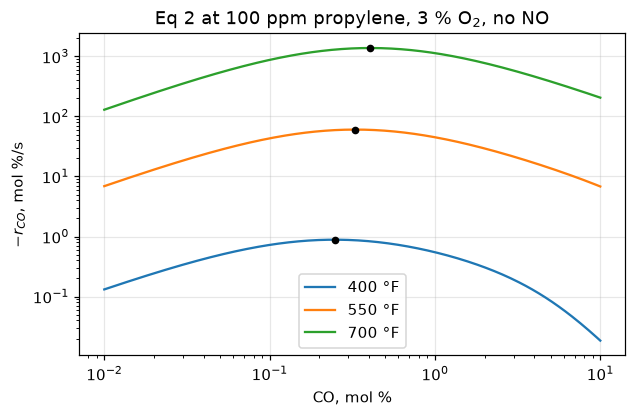

The rate peaks at 0.247 % CO at 400 °F, 0.330 % at 550 °F and 0.406 % at 700 °F (100 ppm propylene). 7 of the 7 feeds of Figures 19 and 20 start above the maximum at their own propylene (by a factor 1.09 at least), so at the inlet of every run CO inhibits its own oxidation. The maximum moves to higher CO with temperature because $k_{a_1}$ has a negative activation energy: the inhibition weakens as the catalyst warms.

In [6]:
co = np.logspace(-2, 1, 300)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for T in (400.0, 550.0, 700.0):
    kT = rate_constants(PAR, T)
    r = rates(kT, co, 50.0, 3.0, 0.0)[0]
    ax.loglog(co, r, label=f"{T:.0f} °F")
    ax.plot(base[f"co_max_{T:.0f}F"], rates(kT, base[f"co_max_{T:.0f}F"], 50.0, 3.0, 0.0)[0],
            "ko", ms=4)
ax.set_xlabel("CO, mol %")
ax.set_ylabel("$-r_{CO}$, mol %/s")
ax.set_title("Eq 2 at 100 ppm propylene, 3 % O$_2$, no NO")
ax.legend()
plt.show()
display(Markdown(
    f"The rate peaks at {base['co_max_400F']:.3f} % CO at 400 °F, "
    f"{base['co_max_550F']:.3f} % at 550 °F and {base['co_max_700F']:.3f} % at 700 °F "
    f"(100 ppm propylene). {claims['feeds_above_max']} of the {len(COND)} feeds of "
    "Figures 19 and 20 start above the maximum at their own propylene (by a factor "
    f"{min(base['feed_over_max']):.2f} at least), so at the inlet of every run CO "
    "inhibits its own oxidation. The maximum moves to higher CO with temperature "
    "because $k_{a_1}$ has a negative activation energy: the inhibition weakens as "
    "the catalyst warms."))

### Which ppm basis the constants were fitted with

For each calculated-line point, the space velocity read off the authors' line
times the space time at which this page's reactor reaches the same conversion
is $a$. If the page computes what the authors computed, $a$ is one number for
all 13 points, whatever the gas-volume basis.

In [7]:
la_c6 = np.log10(a_per_point(PAR, 2.0, True, N_CELLS))
tab = lines.assign(**{"a, ppm as C6": 10 ** la_c6,
                      "deviation, dex": la_c6 - la_c6.mean()})
show(tab.style.hide(axis="index").format({"space_velocity": "{:.3g}", "a, ppm as C6": "{:.4f}",
                                          "deviation, dex": "{:+.3f}"}), "c2132")
display(Markdown(
    f"With propylene in ppm as C6 the 13 values of $a$ scatter by "
    f"{base['a_spread_dex']:.3f} dex (standard deviation of $\\log_{{10}} a$); "
    f"with propylene in plain ppm by {base['a_spread_other_basis_dex']:.3f} dex, "
    f"{base['a_spread_other_basis_dex'] / base['a_spread_dex']:.1f} times more. The C6 "
    "basis is the one the paper's text defines and the one its curves follow. The "
    f"largest remaining deviation is point {base['largest_dev_point']} (figure and "
    f"curve), {base['largest_dev_margin_dex']:.3f} dex ahead of the next."))
display(Markdown(
    f"Without O2 depletion the 13 values scatter by {base['a_spread_no_o2_dex']:.3f} dex "
    f"and $a$ = {base['a_fit_no_o2']:.4f}: the calculated lines do not decide whether "
    "the authors depleted O2."))

figure,species,curve,conversion_pct,space_velocity,"a, ppm as C6","deviation, dex"
19,CO,A,50,0.257,0.0315,+0.123
19,CO,B,50,0.383,0.0266,+0.049
19,CO,C,50,0.907,0.0226,-0.021
19,CO,D,50,1.86,0.0228,-0.018
19,CO,E,50,2.91,0.0232,-0.010
19,CO,F,50,3.97,0.0247,+0.016
19,CO,G,50,5.93,0.0243,+0.010
20,C3H6,A,40,0.165,0.0223,-0.028
20,C3H6,B,40,0.324,0.0254,+0.029
20,C3H6,C,40,0.725,0.0208,-0.058


With propylene in ppm as C6 the 13 values of $a$ scatter by 0.047 dex (standard deviation of $\log_{10} a$); with propylene in plain ppm by 0.143 dex, 3.0 times more. The C6 basis is the one the paper's text defines and the one its curves follow. The largest remaining deviation is point 19A (figure and curve), 0.051 dex ahead of the next.

Without O2 depletion the 13 values scatter by 0.041 dex and $a$ = 0.0224: the calculated lines do not decide whether the authors depleted O2.

### The integral reactor against Figures 19 and 20

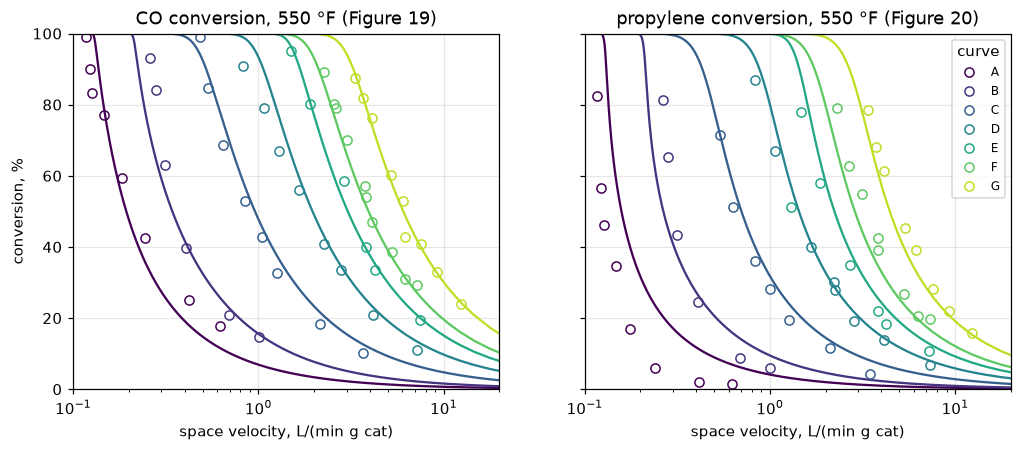

With $a$ = 0.0238 s·L/(min·g) from the calculated lines, the model misses the CO markers by 6.3 percentage points (root mean square, mean -0.9) and the propylene markers by 14.7 (mean +2.7). The value of $a$ is 0.59 times $a_0$ (the value with $F$ at 550 °F, the space velocity in litres at 0 °C and the stated bulk density): the paper's basis for the gas volume and the catalyst volume is not recoverable from its text, and no basis it states reproduces its curves without this factor.

The mean misses are -0.90 ± 0.85 (CO) and +2.66 ± 2.03 (propylene) percentage points, mean ± standard error. Figure 20 curve A dominates the propylene miss (root mean square 28.4, mean +24.1), while the model matches the authors' own line for that curve to -0.028 dex in $a$: that miss is the paper's own.

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.9, 7))
for ax, fig_no, j, name in ((axs[0], 19, 0, "CO"), (axs[1], 20, 1, "propylene")):
    for col, (c, inlet) in zip(colors, COND.items()):
        g = obs[(obs.figure == fig_no) & (obs.curve == c)]
        tau_max = base["a_fit"] / 0.1
        rx = IntegralReactor(PAR, T_FIG, inlet, n=N_CELLS)
        rx.solve(tau_max)
        u = rx.u[:, j]
        ax.semilogx(base["a_fit"] / (tau_max * rx.x_c), 100 * (1 - u), color=col)
        ax.semilogx(g.space_velocity, g.conversion_pct, "o", mfc="none", color=col, label=c)
    ax.set_xlim(0.1, 20)
    ax.set_ylim(0, 100)
    ax.set_xlabel("space velocity, L/(min g cat)")
    ax.set_title(f"{name} conversion, 550 °F (Figure {fig_no})")
axs[0].set_ylabel("conversion, %")
axs[1].legend(title="curve", fontsize=8)
plt.show()
display(Markdown(
    f"With $a$ = {base['a_fit']:.4f} s·L/(min·g) from the calculated lines, the "
    f"model misses the CO markers by {base['rms_fig19_pp']:.1f} percentage points "
    f"(root mean square, mean {base['bias_fig19_pp']:+.1f}) and the propylene markers "
    f"by {base['rms_fig20_pp']:.1f} (mean {base['bias_fig20_pp']:+.1f}). The value of "
    f"$a$ is {base['a_fit_over_a_0C']:.2f} times $a_0$ (the value with $F$ at 550 °F, "
    "the space velocity in litres at 0 °C and the stated bulk density): the paper's basis for the gas volume and the catalyst "
    "volume is not recoverable from its text, and no basis it states reproduces its "
    "curves without this factor."))
display(Markdown(
    f"The mean misses are {base['bias_fig19_pp']:+.2f} ± {base['bias_se_fig19_pp']:.2f} "
    f"(CO) and {base['bias_fig20_pp']:+.2f} ± {base['bias_se_fig20_pp']:.2f} "
    "(propylene) percentage points, mean ± standard error. Figure 20 curve A dominates the "
    f"propylene miss (root mean square {base['rms_20A_pp']:.1f}, mean "
    f"{base['bias_20A_pp']:+.1f}), while the model matches the authors' own line for that "
    f"curve to {base['dev_20A_dex']:+.3f} dex in $a$: that miss is the paper's own."))

## Validation

- **The authors' calculation reproduced:** the spread of $a$ over the 13
  calculated-line points, above.
- **Oh and Cavendish's constants:** `I1.2`'s statement that the adsorption
  constants and activation energies are Voltz's, unit-converted at face value, is checked
  (mol % to mole fraction is a factor 100, ppm to mole fraction $10^6$, °R to
  K a factor 1.8).
- **Closed-form limit:** with $k_{a_3}=0$ the root of the derivative equals
  $(1 + k_{a_2}\mathrm{C_3H_6})/k_{a_1}$.
- **Discretisation:** the pymrm reactor against an independent `solve_ivp`
  march of the same equations at every calculated-line point, and the observed
  order of the outlet conversion of curve A on a ladder of grids.

In [9]:
display(Markdown(
    f"Oh and Cavendish's adsorption pre-exponentials agree with Voltz's converted ones "
    f"to a relative {base['oc_K_pre_max_relgap']:.1e} at worst, and their activation "
    f"temperatures to {base['oc_E_max_gap_K']:.2f} K: `I1.2`'s statement holds to the "
    "printed digits. With $k_{a_3}=0$ the root and the closed form of the CO maximum "
    "differ by a relative amount below 1e-9, the find_roots tolerance "
    f"(here {base['co_max_closed_form_relgap']:.0e}). On {N_CELLS} cells the pymrm reactor is within "
    f"{base['pymrm_vs_march_max_pp']:.3f} percentage points of the march at every "
    f"point; the observed order is {base['order_min']:.2f} to {base['order_max']:.2f} "
    "(first-order upwind), on a finest difference of "
    f"{base['finest_difference_pp']:.1e} percentage points, far above round-off."))

Oh and Cavendish's adsorption pre-exponentials agree with Voltz's converted ones to a relative 7.6e-04 at worst, and their activation temperatures to 0.44 K: `I1.2`'s statement holds to the printed digits. With $k_{a_3}=0$ the root and the closed form of the CO maximum differ by a relative amount below 1e-9, the find_roots tolerance (here 2e-15). On 800 cells the pymrm reactor is within 0.075 percentage points of the march at every point; the observed order is 1.00 to 1.00 (first-order upwind), on a finest difference of 8.3e-03 percentage points, far above round-off.

In [10]:
# Claims: every number above, with how it is checked, and the break table.
claims.value("kr1_550F", base["kr1_550F"], unit="1/(s mol% O2)")
claims.value("ka1_550F", base["ka1_550F"], unit="1/mol%")
claims.bound("oc_K_pre_max_relgap", base["oc_K_pre_max_relgap"], max=5e-3, basis="chosen",
             note="three printed significant figures on either side")
claims.bound("oc_E_max_gap_K", base["oc_E_max_gap_K"], max=0.5, basis="chosen",
             note="I1.2 prints integer kelvin")
for T in (400, 550, 700):
    claims.value(f"co_max_{T}F", base[f"co_max_{T}F"], unit="mol%")
claims.bound("co_max_closed_form_relgap", base["co_max_closed_form_relgap"], max=1e-9,
             basis="tolerance", note="find_roots xtol 1e-12 on a root near 0.3")
claims.exact("co_max_rises_with_T", bool(base["co_max_rise_min"] > 0),
             margin=abs(base["co_max_rise_min"]), min_margin=0.05)
claims.value("a_fit", base["a_fit"], unit="s L/(min g)")
claims.exact("largest_dev_point", base["largest_dev_point"],
             margin=base["largest_dev_margin_dex"], min_margin=0.01)
claims.value("a_spread_dex", base["a_spread_dex"], unit="dex")
claims.value("a_spread_other_basis_dex", base["a_spread_other_basis_dex"], unit="dex")
claims.value("a_fit_over_a_0C", base["a_fit_over_a_0C"])
claims.value("a_spread_no_o2_dex", base["a_spread_no_o2_dex"], unit="dex")
claims.value("a_fit_no_o2", base["a_fit_no_o2"], unit="s L/(min g)")
claims.value("dev_20A_dex", base["dev_20A_dex"], atol=0.01, unit="dex")
claims.value("rms_20A_pp", base["rms_20A_pp"], unit="percentage points")
claims.value("bias_20A_pp", base["bias_20A_pp"], rtol=0.1, unit="percentage points")
for fig_no in (19, 20):
    claims.value(f"bias_se_fig{fig_no}_pp", base[f"bias_se_fig{fig_no}_pp"], unit="percentage points")
for fig_no in (19, 20):
    claims.value(f"rms_fig{fig_no}_pp", base[f"rms_fig{fig_no}_pp"], unit="percentage points")
    claims.value(f"bias_fig{fig_no}_pp", base[f"bias_fig{fig_no}_pp"], rtol=0.1,
                 unit="percentage points")
claims.bound("pymrm_vs_march_max_pp", base["pymrm_vs_march_max_pp"], max=0.15, basis="chosen",
             note="first-order upwind on 800 cells, error falling as 1/n (order claims)")
claims.bound("order_min", base["order_min"], min=0.9, max=1.1, basis="theory")
claims.bound("order_max", base["order_max"], min=0.9, max=1.1, basis="theory")
claims.bound("finest_difference_pp", base["finest_difference_pp"], min=1e-9, basis="theory",
             note="at least 1e3 times round-off of a percentage")

P10 = lambda key, f: dict(PAR, **{key: PAR[key] * f})  # noqa: E731
ROWS = [
    ("Table I k0_r1 10 % high", lambda: study(par=P10("k0_r1", 1.1))),
    ("Table I k0_r2 10 % high", lambda: study(par=P10("k0_r2", 1.1))),
    ("Table I k0_a1 10 % high", lambda: study(par=P10("k0_a1", 1.1))),
    ("Table I k0_a2 read as 2.80e-3", lambda: study(par=dict(PAR, k0_a2=2.80e-3))),
    ("Table I E_a2 read as -560", lambda: study(par=dict(PAR, E_a2=-560.0))),
    ("Table I k0_a3 read as 3.98e-15", lambda: study(par=dict(PAR, k0_a3=3.98e-15))),
    ("Table I E_a1 with its sign lost", lambda: study(par=dict(PAR, E_a1=1730.0))),
    ("propylene in plain ppm in the rates", lambda: study(hc_basis=1.0)),
    ("O2 not consumed", lambda: study(o2_consumed=False)),
    ("adsorption-group exponent 1 in the maximum (no root: d ln r/dCO > 0)",
     lambda: study(power=1)),
    ("march reference without O2 consumption", lambda: study(march_o2=False)),
    ("pymrm reactor on 100 cells", lambda: study(n=100)),
    ("refinement ratio declared as 3 for a ladder of 2 (refused, nan)",
     lambda: study(ratio=3.0)),
    ("ladder without refinement, one grid four times (refused, nan)",
     lambda: study(ladder=(800, 800, 800, 800), ratio=1.0)),
    ("ladder on 10 to 80 cells, outside the asymptotic range",
     lambda: study(ladder=(10, 20, 40, 80))),
]
claims.define_rows([label for label, _ in ROWS])
BREAK = []
for label, run in ROWS:
    with np.errstate(all="ignore"):
        broken = run()
    for name in broken:
        if name in claims.metrics:
            BREAK.append((label, name, base[name], broken[name],
                          claims.breaks(label, name, broken[name])))
bt = pd.DataFrame(BREAK, columns=["injected defect", "claim", "clean", "with defect", "caught"])
caught = bt.groupby("claim").caught.any()
fmt = lambda v: f"{v:.4g}" if isinstance(v, float) else str(v)  # noqa: E731
show(bt[bt.caught].style.hide(axis="index").format({"clean": fmt, "with defect": fmt}), "c2133")
print(f"{len(ROWS)} rows; claims caught by at least one row: {int(caught.sum())} of "
      f"{len(caught)}; not caught: {sorted(caught[~caught].index) or 'none'}")

injected defect,claim,clean,with defect,caught
Table I k0_r1 10 % high,kr1_550F,350.4,385.4,True
Table I k0_r1 10 % high,a_fit,0.02377,0.02221,True
Table I k0_r1 10 % high,a_spread_dex,0.04722,0.04251,True
Table I k0_r1 10 % high,a_fit_over_a_0C,0.5857,0.5472,True
Table I k0_r1 10 % high,a_spread_no_o2_dex,0.04094,0.03562,True
Table I k0_r1 10 % high,a_fit_no_o2,0.0224,0.0209,True
Table I k0_r1 10 % high,bias_fig19_pp,-0.8957,0.2303,True
Table I k0_r1 10 % high,bias_fig20_pp,2.662,1.533,True
Table I k0_r2 10 % high,a_spread_dex,0.04722,0.0542,True
Table I k0_r2 10 % high,a_spread_no_o2_dex,0.04094,0.04845,True


15 rows; claims caught by at least one row: 30 of 30; not caught: none


## What pymrm adds

The rate law itself needs no solver. pymrm contributes the integral reactor of
eq 1 as a reusable steady model (operators assembled once, a `NumJac`
Jacobian for the three coupled species, one bounded `newton` solve per space
time) and `pymrm.checks` for the roots (the CO maximum, the space time at a
conversion) and the observed order. With it the page shows two things the
paper does not state: the propylene ppm of its feeds enter the rates halved,
as its "ppm of propylene (as C6 FID)" implies, and the space velocities of the
figures relate to $V/F$ by a factor no stated basis explains. A `solve_ivp` march computes the same reactor; the pymrm form
is what carries over to the dispersed, non-isothermal and monolith models
that reuse these kinetics (`I1.2`).

## Reuse

- **Units.** Table I takes CO and O2 in mol %, propylene and NO in ppm, and
  temperature as °F + 460 in the exponentials. Propylene enters the rates in
  ppm as C6, half the propylene ppm; using propylene ppm directly overstates
  its inhibition and spreads the reconstruction of the paper's own curves
  (the table above).
- **Space velocity.** Before comparing with the paper's figures, fix $a$ from
  its calculated curves as above; the stated bulk density with $F$ at 550 °F and the space velocity in litres at
  0 °C do not reproduce them.
- **Rate constants per platinum area** for a monolith: `I1.2` (Oh and
  Cavendish), whose adsorption constants are these converted with propylene ppm at face
  value; on the C6 basis found here, $K_2$ and $K_3$ for propylene mole
  fractions are half and a quarter of theirs.
- Related pages: `I1.2` (converter light-off with these kinetics), `C1.1`
  (the Hougen-Watson formalism these forms come from), `C2.1` and `C2.10`
  (other LHHW kinetics in integral reactors).

In [11]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for C2.13:
  feeds_above_max           = 7                exact  exact, margin 0.0875
  kr1_550F                  = 350.41           value  rtol 0.05
  ka1_550F                  = 3.6319           value  rtol 0.05
  oc_K_pre_max_relgap       = (here 7.6e-04)   bound  bound <= 0.005 [chosen]
  oc_E_max_gap_K            = (here 4.4e-01)   bound  bound <= 0.5 [chosen]
  co_max_400F               = 0.2473           value  rtol 0.05
  co_max_550F               = 0.3297           value  rtol 0.05
  co_max_700F               = 0.40617          value  rtol 0.05
  co_max_closed_form_relgap = (here 2.2e-15)   bound  bound <= 1e-09 [tolerance]
  co_max_rises_with_T       = True             exact  exact, margin 0.232
  a_fit                     = 0.023769         value  rtol 0.05
  largest_dev_point         = '19A'            exact  exact, margin 0.051
  a_spread_dex              = 0.047219         value  rtol 0.05
  a_spread_other_basis_dex  = 0.14344          value  rtol 0.05
  a_fit_over